In [1]:
import os
BASE_DIR = "\\notebooks\\experiments"
if os.getcwd().endswith(BASE_DIR):
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), '..', '..')))

from src.models.model_handler import load_model
from src.models.testing_utils import evaluate_continuous, predict_continuous
from src.data.DatasetGenerator import DatasetGenerator
from src.utils.helpers import load_param
from src.data.preprocessing import generate_tensors

In [18]:
def value_difference(hurst):
    prova_carrega_model=load_model("models\FractionalBrownianMotionHurstRegressor.pth")

    dg = DatasetGenerator(100)
    dataset = dg.generate_FractionalBrownianMotion(num_passos=200, hurst=hurst)
    x, y = generate_tensors(dataset, "hurst")
    results = predict_continuous(prova_carrega_model, x, y, num_samples=10, to_print=False)
    return results["Predicción"].mean().item(), results["Valor real"][0].item()

<>:2: SyntaxWarning: invalid escape sequence '\F'
<>:2: SyntaxWarning: invalid escape sequence '\F'
C:\Users\jmass\AppData\Local\Temp\ipykernel_48268\2518474853.py:2: SyntaxWarning: invalid escape sequence '\F'
  prova_carrega_model=load_model("models\FractionalBrownianMotionHurstRegressor.pth")


In [23]:
print(value_difference(hurst=0.1))
print(value_difference(hurst=0.3))
print(value_difference(hurst=0.5))
print(value_difference(hurst=0.7))
print(value_difference(hurst=0.9))

(0.06257710605859756, 0.0)
(0.335027277469635, 0.25)
(0.7568701505661011, 0.5)
(0.8550299406051636, 0.75)


c:\Users\jmass\Documents\GitHub\TFG_GEINF\env\Lib\site-packages\fbm\fbm.py:171: UserWarning: Combination of increments n and Hurst value H invalid for Davies-Harte method. Reverting to Hosking method. Occurs when n is small and Hurst is close to 1. 
  warnings.warn(


(0.8861768841743469, 1.0)


c:\Users\jmass\Documents\GitHub\TFG_GEINF\env\Lib\site-packages\fbm\fbm.py:171: UserWarning: Combination of increments n and Hurst value H invalid for Davies-Harte method. Reverting to Hosking method. Occurs when n is small and Hurst is close to 1. 
  warnings.warn(


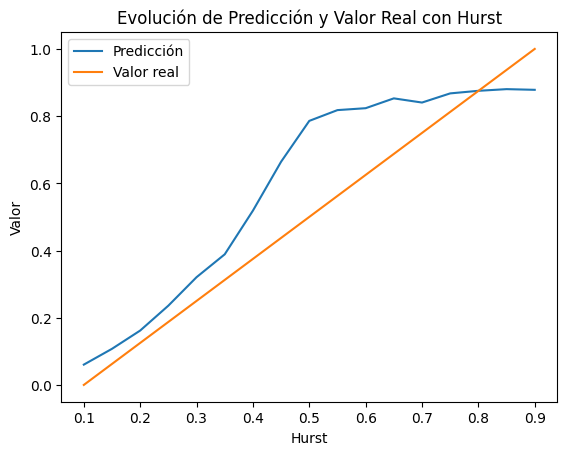

In [24]:
import numpy as np

import matplotlib.pyplot as plt

hurst_values = np.arange(0.1, 0.91, 0.05)
predichos = []
reales = []

for h in hurst_values:
    pred, real = value_difference(h)
    predichos.append(pred)
    reales.append(real)

plt.plot(hurst_values, predichos, label='Predicción')
plt.plot(hurst_values, reales, label='Valor real')
plt.xlabel('Hurst')
plt.ylabel('Valor')
plt.title('Evolución de Predicción y Valor Real con Hurst')
plt.legend()
plt.show()

0.375